### Create a new feature to categorize customers into different age groups by dynamically determining optimal age bins using clustering techniques (e.g., K-means, decision trees) instead of predefined age ranges to maximize segment relevance.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [3]:
age_data = df[["Age"]].dropna().copy()

print("Missing Age Values:", df["Age"].isnull().sum())
print("Minimum Age:", age_data["Age"].min())
print("Maximum Age:", age_data["Age"].max())
print("Valid Age Records:", len(age_data))

Missing Age Values: 0
Minimum Age: 18
Maximum Age: 99
Valid Age Records: 23486


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [5]:
X_age = age_data[["Age"]]
scores = {}
max_k = min(10, X_age["Age"].nunique() - 1)

for k in range(2, max_k + 1):
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = model.fit_predict(X_age)
    score = silhouette_score(X_age, labels)
    scores[k] = score
    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

best_k = max(scores, key=scores.get)

print("\nSelected Number of Clusters:", best_k)
print("Best Silhouette Score:", round(scores[best_k], 4))

Clusters: 2, Silhouette Score: 0.5981
Clusters: 3, Silhouette Score: 0.5391
Clusters: 4, Silhouette Score: 0.5410
Clusters: 5, Silhouette Score: 0.5447
Clusters: 6, Silhouette Score: 0.5418
Clusters: 7, Silhouette Score: 0.5527
Clusters: 8, Silhouette Score: 0.5356
Clusters: 9, Silhouette Score: 0.5349
Clusters: 10, Silhouette Score: 0.5450

Selected Number of Clusters: 2
Best Silhouette Score: 0.5981


In [6]:
## Create the new Age Group feature
kmeans = KMeans(n_clusters=best_k,random_state=42,n_init=10)
age_data["Age Cluster"] = kmeans.fit_predict(X_age)

# Arrange clusters from youngest to oldest
cluster_order = (age_data.groupby("Age Cluster")["Age"].mean().sort_values().index)

# Assign meaningful labels based on cluster order
cluster_names = {
    cluster: f"Age Group {i + 1}"
    for i, cluster in enumerate(cluster_order)
}

age_data["Age Group"] = age_data["Age Cluster"].map(cluster_names)
# Add the feature to the original dataset
df["Age Group"] = pd.NA
df.loc[age_data.index, "Age Group"] = age_data["Age Group"]
print(df[["Age", "Age Group"]])

       Age    Age Group
0       33  Age Group 1
1       34  Age Group 1
2       60  Age Group 2
3       50  Age Group 2
4       47  Age Group 2
...    ...          ...
23481   34  Age Group 1
23482   48  Age Group 2
23483   31  Age Group 1
23484   28  Age Group 1
23485   52  Age Group 2

[23486 rows x 2 columns]


In [7]:
## age group 
age_summary = (
    age_data.groupby("Age Group")
    .agg(
        Customer_Count=("Age", "count"),
        Minimum_Age=("Age", "min"),
        Maximum_Age=("Age", "max"),
        Average_Age=("Age", "mean")
    )
    .round(2)
)

print("========== AGE GROUP SUMMARY ==========")
print(age_summary)

========== AGE GROUP SUMMARY ==========
             Customer_Count  Minimum_Age  Maximum_Age  Average_Age
Age Group                                                         
Age Group 1           14367           18           45        35.11
Age Group 2            9119           46           99        55.94


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

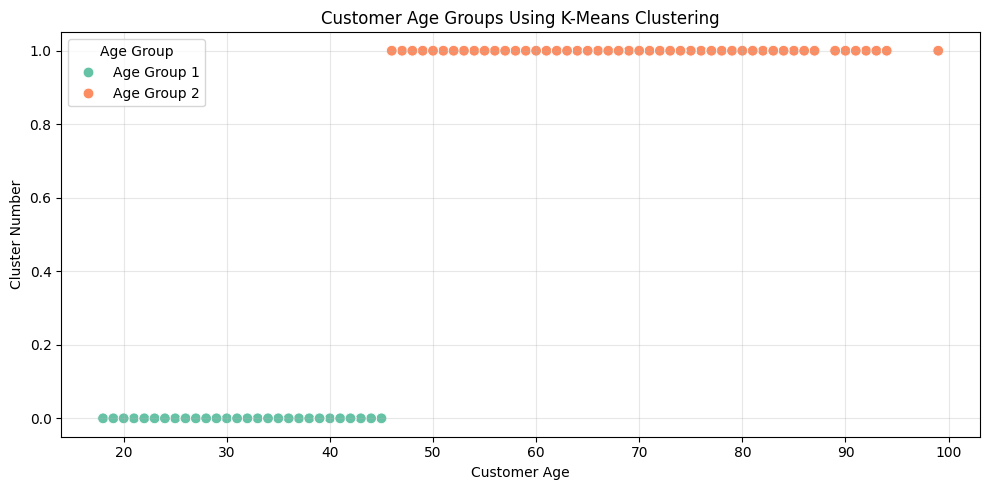

In [9]:
## Visualize the optimal clusters
plt.figure(figsize=(10, 5))

sns.scatterplot(data=age_data,x="Age",y="Age Cluster",hue="Age Group",palette="Set2",s=60)

plt.title("Customer Age Groups Using K-Means Clustering")
plt.xlabel("Customer Age")
plt.ylabel("Cluster Number")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

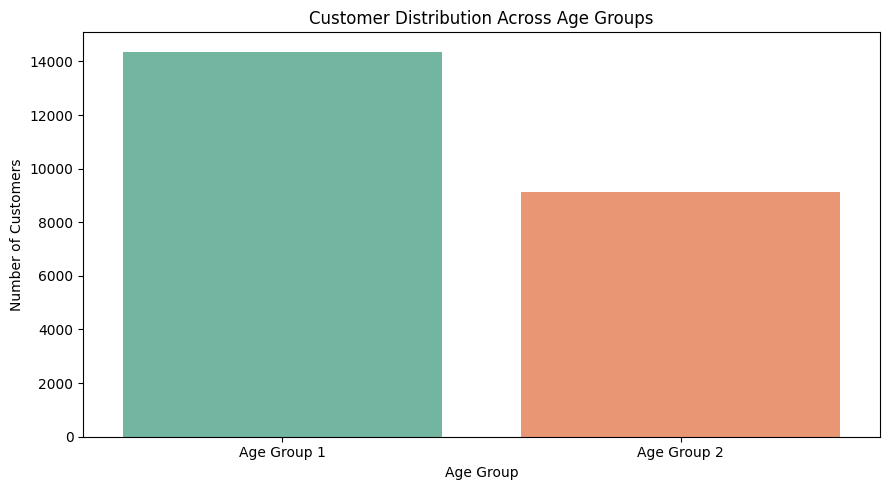

In [10]:
## Plot customer distribution
plt.figure(figsize=(9, 5))

sns.countplot(data=age_data,x="Age Group",hue="Age Group",order=[cluster_names[c] for c in cluster_order],palette="Set2",legend=False)

plt.title("Customer Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Decision Tree

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

In [12]:
# Select required columns and remove missing values
tree_df = df[["Age", "Recommended IND"]].dropna().copy()

X = tree_df[["Age"]]
y = tree_df["Recommended IND"]

print("Dataset Shape:", tree_df.shape)
print("Missing Values:\n", tree_df.isnull().sum())
print("Target Distribution:\n", y.value_counts())

Dataset Shape: (23486, 2)
Missing Values:
 Age                0
Recommended IND    0
dtype: int64
Target Distribution:
 Recommended IND
1    19314
0     4172
Name: count, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42,stratify=y)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print()

print("Training outcome counts")
print(y_train.value_counts())
print()

print("Testing outcome counts")
print(y_test.value_counts())

Training set size: (18788, 1)
Testing set size: (4698, 1)

Training outcome counts
Recommended IND
1    15451
0     3337
Name: count, dtype: int64

Testing outcome counts
Recommended IND
1    3863
0     835
Name: count, dtype: int64


In [14]:
decision_tree_model= DecisionTreeClassifier(max_leaf_nodes=5,min_samples_leaf=100,random_state=42)
decision_tree_model.fit(X_train, y_train)
print("Random Forest model trained") 

Random Forest model trained


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
y_pred_decisiontree = decision_tree_model.predict(X_test)

# Calculate scores
accuracy = accuracy_score(y_test, y_pred_decisiontree)
precision = precision_score(y_test, y_pred_decisiontree)
recall = recall_score(y_test, y_pred_decisiontree)
f1 = f1_score(y_test, y_pred_decisiontree)

# Print scores
print("Decision Tree Model Scores")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Decision Tree Model Scores
Accuracy: 0.82
Precision: 0.82
Recall: 1.00
F1-Score: 0.90


In [16]:
#Use the trained tree to assign each customer to a leaf
tree_df["Age Group ID"] = decision_tree_model.apply(X)

# Rename leaf IDs in increasing average-age order
leaf_order = (tree_df.groupby("Age Group ID")["Age"].mean().sort_values().index)

leaf_names = {
    leaf_id: f"Age Group {i + 1}"
    for i, leaf_id in enumerate(leaf_order)
}

tree_df["Age Group"] = tree_df["Age Group ID"].map(leaf_names)

# Add new feature to original dataset
df["Age Group (Decision Tree)"] = pd.NA

df.loc[tree_df.index, "Age Group (Decision Tree)"] = (tree_df["Age Group"])

print(df[ ["Age", "Recommended IND", "Age Group (Decision Tree)"]])

       Age  Recommended IND Age Group (Decision Tree)
0       33                1               Age Group 2
1       34                1               Age Group 2
2       60                0               Age Group 5
3       50                1               Age Group 5
4       47                1               Age Group 4
...    ...              ...                       ...
23481   34                1               Age Group 2
23482   48                1               Age Group 4
23483   31                0               Age Group 2
23484   28                1               Age Group 2
23485   52                1               Age Group 5

[23486 rows x 3 columns]


In [17]:
age_group_summary = (
    tree_df.groupby("Age Group")
    .agg(
        Customer_Count=("Age", "count"),
        Minimum_Age=("Age", "min"),
        Maximum_Age=("Age", "max"),
        Recommendation_Rate=("Recommended IND", "mean")
    )
    .round(3)
)

age_group_summary["Recommendation_Rate"] *= 100

print("========== DECISION TREE AGE GROUP SUMMARY ==========")
print(age_group_summary)

========== DECISION TREE AGE GROUP SUMMARY ==========
             Customer_Count  Minimum_Age  Maximum_Age  Recommendation_Rate
Age Group                                                                 
Age Group 1             647           18           23                 87.8
Age Group 2            8717           24           38                 80.1
Age Group 3            1269           39           39                 87.3
Age Group 4            5637           40           48                 81.0
Age Group 5            7216           49           99                 84.4


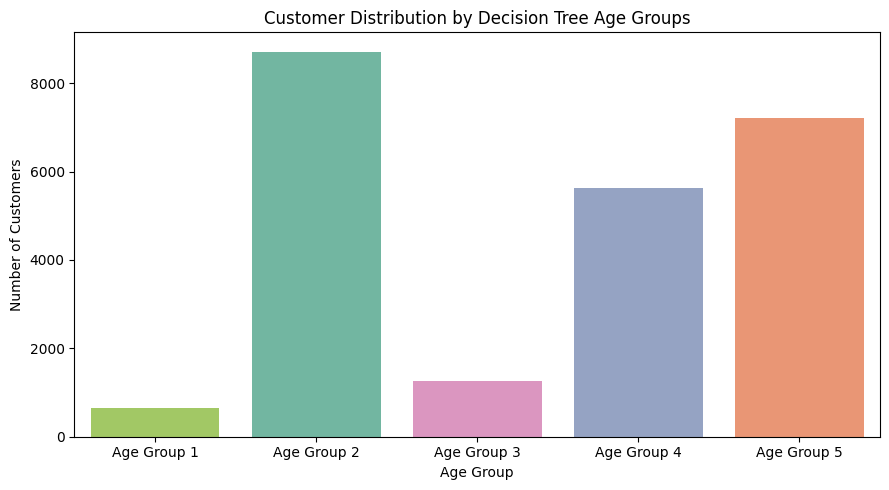

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(data=tree_df,x="Age Group",hue="Age Group",order=[leaf_names[x] for x in leaf_order], palette="Set2",legend=False)

plt.title("Customer Distribution by Decision Tree Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()